# Logistic Regression

In [19]:
# Implementation 1

from itertools import product
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

from imblearn.over_sampling import SMOTE

from preprocessing import prepare_data

TRAIN_FRAC, VAL_FRAC = 0.70, 0.15       # do dataset global
C_GRID = [0.001, 0.01, 0.1, 1, 10, 100]
PENALTIES = ["l2", "l1"]
CLASS_WEIGHTS = [None, "balanced"]
STRATEGIES = ("drop_rows", "drop_features", "global_median",
              "season_median", "doy_window_median")
SPLIT_TESTS = ("recent","recent20", "recent19", "stratified")
CONT_COLS = ["SST", "UI", "YDOY", "sin_doy", "CHL_log", "CHL_uncertainty"]


def configs():
    """Grelha (C pequeno = mais regularização primeiro: em empates fica o mais simples)."""
    for pen in PENALTIES:
        for cw in CLASS_WEIGHTS:
            for C in C_GRID:
                yield {"penalty": pen, "C": C, "class_weight": cw}


def make_lr(cfg):
    solver = "lbfgs" if cfg["penalty"] == "l2" else "liblinear"
    return LogisticRegression(penalty=cfg["penalty"], C=cfg["C"],
                              class_weight=cfg["class_weight"],
                              solver=solver, max_iter=5000, random_state=0)



def split_train_val(X, y, dates, train_frac=TRAIN_FRAC, val_frac=VAL_FRAC):
    """Separa train/val cronologicamente, em datas inteiras."""
    order = np.argsort(dates.to_numpy(), kind="stable")
    X, y, dates = X.iloc[order], y.iloc[order], dates.iloc[order]
    n_val = int(round(len(X) * val_frac / (train_frac + val_frac)))
    cutoff = dates.iloc[len(X) - n_val]
    is_val = (dates >= cutoff).to_numpy()
    return X[~is_val], y[~is_val], X[is_val], y[is_val]


def standardize(X_fit, *others):
    """Standardiza as contínuas com média/desvio (ddof=0) de X_fit."""
    cont = [c for c in CONT_COLS if c in X_fit.columns]
    mu = X_fit[cont].mean()
    sd = X_fit[cont].std(ddof=0).replace(0, 1.0)

    def f(X):
        X = X.copy().astype(float)
        X[cont] = (X[cont] - mu) / sd
        return X.to_numpy()

    return tuple(f(X) for X in (X_fit,) + others)


def best_f1_threshold(y_true, p):
    prec, rec, thr = precision_recall_curve(y_true, p)
    f1 = 2 * prec[:-1] * rec[:-1] / np.maximum(prec[:-1] + rec[:-1], 1e-12)
    return float(thr[np.argmax(f1)])


def p1(model, A):
    return model.predict_proba(A)[:, list(model.classes_).index(1)]


def run_lr(strategy, split_test, refit=True, season="one_hot", verbose=False, **kw):
    Xtv, ytv, Xte, yte, dtv, _ = prepare_data(
        strategy, split_test, one_hot_cluster=True, sin_doy=True,
        season=season, scale=False, return_dates=True, **kw)
    Xtr, ytr, Xva, yva = split_train_val(Xtv, ytv, dtv)
    Atr, Ava = standardize(Xtr, Xva)                    # scaling só com o train

    # Apply SMOTE ONLY to the scaled training set
    smote = SMOTE(sampling_strategy="auto", k_neighbors=5, random_state=42)
    Atr_sm, ytr_sm = smote.fit_resample(Atr, ytr)

    print("Before SMOTE:", ytr.value_counts().to_dict())
    print("After SMOTE: ", pd.Series(ytr_sm).value_counts().to_dict())

    best = {"auc": -np.inf}
    for cfg in configs():
        m = make_lr(cfg).fit(Atr_sm, ytr_sm)
        p_val = p1(m, Ava)
        auc = roc_auc_score(yva, p_val)
        if verbose:
            print(f"  {cfg}  val AUC={auc:.4f}")
        if auc > best["auc"]:                          
            best = {"auc": auc, "cfg": cfg, "p_val": p_val}
    cfg = best["cfg"]

    thr = best_f1_threshold(yva, best["p_val"])

    if refit:
        Afit, Ate = standardize(Xtv, Xte)               
        yfit = ytv
    else:
        Afit, Ate = standardize(Xtr, Xte)
        yfit = ytr

    Afit_sm, yfit_sm = smote.fit_resample(Afit, yfit)
    final = make_lr(cfg).fit(Afit_sm, yfit_sm)
    p_test = p1(final, Ate)
    y_pred = (p_test >= thr).astype(int)

    return {"strategy": strategy, "split_test": split_test,
            "n_train": len(Xtr), "n_val": len(Xva), "n_test": len(Xte),
            "penalty": cfg["penalty"], "C": cfg["C"],
            "class_weight": cfg["class_weight"],
            "val_AUC": best["auc"],
            "test_AUC": roc_auc_score(yte, p_test),
            "test_PR_AUC": average_precision_score(yte, p_test),
            "thr": thr,
            "accuracy": accuracy_score(yte, y_pred),
            "recall": recall_score(yte, y_pred, zero_division=0),
            "precision": precision_score(yte, y_pred, zero_division=0),
            "f1": f1_score(yte, y_pred, zero_division=0),
            "_coef": pd.Series(final.coef_[0], index=Xtv.columns)}


if __name__ == "__main__":
    rows = [run_lr(st, sp) for sp in SPLIT_TESTS for st in STRATEGIES]
    pd.set_option("display.width", 250)
    res = pd.DataFrame(rows)
    show = ["split_test", "strategy", "penalty", "C", "class_weight",
            "val_AUC", "test_AUC", "test_PR_AUC", "thr", "accuracy",
            "recall", "precision", "f1"]
    print(res[show].round(3).to_string(index=False))

Before SMOTE: {0: 344, 1: 45}
After SMOTE:  {0: 344, 1: 344}
Before SMOTE: {0: 666, 1: 78}
After SMOTE:  {0: 666, 1: 666}
Before SMOTE: {0: 666, 1: 78}
After SMOTE:  {0: 666, 1: 666}
Before SMOTE: {0: 666, 1: 78}
After SMOTE:  {0: 666, 1: 666}
Before SMOTE: {0: 666, 1: 78}
After SMOTE:  {0: 666, 1: 666}
Before SMOTE: {0: 347, 1: 45}
After SMOTE:  {0: 347, 1: 347}
Before SMOTE: {0: 666, 1: 78}
After SMOTE:  {0: 666, 1: 666}
Before SMOTE: {0: 666, 1: 78}
After SMOTE:  {0: 666, 1: 666}
Before SMOTE: {0: 666, 1: 78}
After SMOTE:  {0: 666, 1: 666}
Before SMOTE: {0: 666, 1: 78}
After SMOTE:  {0: 666, 1: 666}
Before SMOTE: {0: 286, 1: 32}
After SMOTE:  {0: 286, 1: 286}
Before SMOTE: {0: 554, 1: 57}
After SMOTE:  {0: 554, 1: 554}
Before SMOTE: {0: 554, 1: 57}
After SMOTE:  {0: 554, 1: 554}
Before SMOTE: {0: 554, 1: 57}
After SMOTE:  {0: 554, 1: 554}
Before SMOTE: {0: 554, 1: 57}
After SMOTE:  {0: 554, 1: 554}
Before SMOTE: {0: 294, 1: 38}
After SMOTE:  {0: 294, 1: 294}
Before SMOTE: {0: 658, 1

In [20]:
# Implementation 2


C_GRID = [0.01, 0.03, 0.05, 0.1, 0.2, 0.5, 1.0, 2.0, 5.0]
PENALTIES = ["l2", "l1"]
CLASS_WEIGHTS = [None, "balanced"]
STRATEGIES = (
    "drop_rows",
    "drop_features",
    "global_median",
    "season_median",
    "doy_window_median",
)
SPLIT_TESTS = ("recent", "recent20", "recent19", "stratified")
CONT_COLS = ["SST", "UI", "YDOY", "sin_doy", "CHL_log", "CHL_uncertainty"]


def _scale(X_fit: pd.DataFrame, X_other: pd.DataFrame) -> tuple[np.ndarray, np.ndarray]:
    cont = [c for c in CONT_COLS if c in X_fit.columns]
    mu = X_fit[cont].mean()
    sd = X_fit[cont].std(ddof=0).replace(0, 1.0)

    A_fit = X_fit.astype(float).copy()
    A_other = X_other.astype(float).copy()
    A_fit[cont] = (A_fit[cont] - mu) / sd
    A_other[cont] = (A_other[cont] - mu) / sd
    return A_fit.to_numpy(), A_other.to_numpy()


def run_lr(strategy, split_test, n_val_years=3, season="one_hot", verbose=False, **kw):
    Xtv, ytv, Xte, yte, dtv, _ = prepare_data(
        strategy,
        split_test,
        one_hot_cluster=True,
        sin_doy=True,
        season=season,
        scale=False,
        return_dates=True,
        **kw,
    )

    years = dtv.dt.year.to_numpy()
    y_arr = ytv.to_numpy()

    def _valid(mask):
        return mask.sum() >= 20 and np.unique(y_arr[mask]).size == 2

    
    valid_years = [
        yr for yr in np.unique(years)
        if _valid(years == yr) and _valid(years < yr)
    ]
    if valid_years:
        val_years = valid_years[-n_val_years:]
        folds = [(np.flatnonzero(years < yr), np.flatnonzero(years == yr)) for yr in val_years]
    else:
        
        valid_years = [
            yr for yr in np.unique(years)
            if _valid(years == yr) and _valid(years != yr)
        ]
        val_years = valid_years[-n_val_years:]
        folds = [(np.flatnonzero(years != yr), np.flatnonzero(years == yr)) for yr in val_years]

    scaled_folds = [
        (*_scale(Xtv.iloc[tr], Xtv.iloc[va]), y_arr[tr], y_arr[va])
        for tr, va in folds
    ]

    best = {"auc": -np.inf}
    for pen, cw, C in product(PENALTIES, CLASS_WEIGHTS, C_GRID):
        solver = "lbfgs" if pen == "l2" else "liblinear"
        fold_aucs, oof_y, oof_p = [], [], []

        for Atr, Ava, ytr, yva in scaled_folds:
            clf = LogisticRegression(
                penalty=pen, C=C, class_weight=cw, solver=solver, max_iter=5000, random_state=0
            ).fit(Atr, ytr)
            p_va = clf.predict_proba(Ava)[:, 1]
            fold_aucs.append(roc_auc_score(yva, p_va))
            oof_y.append(yva)
            oof_p.append(p_va)

        mean_auc = float(np.mean(fold_aucs))
        if verbose:
            print(f"  penalty={pen}, cw={cw}, C={C} -> val_AUC={mean_auc:.4f}")
        if mean_auc > best["auc"]:
            best = {
                "auc": mean_auc,
                "cfg": {"penalty": pen, "C": C, "class_weight": cw},
                "oof_y": np.concatenate(oof_y),
                "oof_p": np.concatenate(oof_p),
            }

   
    fpr, tpr, thresholds = roc_curve(best["oof_y"], best["oof_p"])
    thr = float(thresholds[1:][np.argmax(tpr[1:] - fpr[1:])])

    
    cfg = best["cfg"]
    solver = "lbfgs" if cfg["penalty"] == "l2" else "liblinear"
    Afit, Ate = _scale(Xtv, Xte)
    final = LogisticRegression(
        penalty=cfg["penalty"],
        C=cfg["C"],
        class_weight=cfg["class_weight"],
        solver=solver,
        max_iter=5000,
        random_state=0,
    ).fit(Afit, y_arr)

    p_test = final.predict_proba(Ate)[:, 1]
    y_pred = (p_test >= thr).astype(int)

    return {
        "strategy": strategy,
        "split_test": split_test,
        "val_years": ",".join(map(str, val_years)),
        "penalty": cfg["penalty"],
        "C": cfg["C"],
        "class_weight": cfg["class_weight"],
        "val_AUC": best["auc"],
        "test_AUC": roc_auc_score(yte, p_test),
        "test_PR_AUC": average_precision_score(yte, p_test),
        "thr": thr,
        "balanced_acc": balanced_accuracy_score(yte, y_pred),
        "recall": recall_score(yte, y_pred, zero_division=0),
        "precision": precision_score(yte, y_pred, zero_division=0),
        "f1": f1_score(yte, y_pred, zero_division=0),
        "_coef": pd.Series(final.coef_[0], index=Xtv.columns),
    }


if __name__ == "__main__":
    rows = [run_lr(st, sp) for sp in SPLIT_TESTS for st in STRATEGIES]
    pd.set_option("display.width", 250)
    res = pd.DataFrame(rows)
    show = [
        "split_test",
        "val_years",
        "strategy",
        "penalty",
        "C",
        "class_weight",
        "val_AUC",
        "test_AUC",
        "test_PR_AUC",
        "thr",
        "balanced_acc",
        "recall",
        "precision",
        "f1",
    ]
    print(res[show].round(3).to_string(index=False))

split_test      val_years          strategy penalty    C class_weight  val_AUC  test_AUC  test_PR_AUC   thr  balanced_acc  recall  precision    f1
    recent 2016,2018,2019         drop_rows      l2 0.20     balanced    0.800     0.849        0.556 0.237         0.721   1.000      0.356 0.525
    recent 2016,2018,2019     drop_features      l1 0.10     balanced    0.858     0.854        0.618 0.552         0.798   0.905      0.475 0.623
    recent 2016,2018,2019     global_median      l1 0.20     balanced    0.837     0.856        0.599 0.431         0.798   0.905      0.475 0.623
    recent 2016,2018,2019     season_median      l1 0.20     balanced    0.835     0.858        0.595 0.439         0.791   0.905      0.463 0.613
    recent 2016,2018,2019 doy_window_median      l1 0.20     balanced    0.816     0.863        0.606 0.436         0.791   0.905      0.463 0.613
  recent20 2016,2018,2019         drop_rows      l2 0.20     balanced    0.800     0.846        0.558 0.237         0.

In [21]:
# Implementation 3
"""
Regressão Logística com validação leave-one-year-out (LOYO) dentro de train_val.

  - hiperparâmetros escolhidos pelo AUC AGREGADO das previsões out-of-fold (todos os anos);
  - imputação e scaling aprendidos só no treino de cada fold (prepare_folds);
  - limiar de decisão escolhido nas mesmas previsões out-of-fold (Youden = max TPR-FPR);
  - modelo final reajustado em todo o train_val; o test só é usado no fim, para reportar.
"""
from itertools import product
import warnings
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, roc_curve, average_precision_score,
                             balanced_accuracy_score, recall_score, precision_score, f1_score)
from preprocessing2 import prepare_data, prepare_folds

warnings.filterwarnings("ignore")

C_GRID = [0.01, 0.03, 0.1, 0.2, 0.3, 1.0, 3.0, 10.0]     # ordem crescente: em empate fica o mais regularizado
PENALTIES = ["l2", "l1"]
CLASS_WEIGHTS = [None, "balanced"]
STRATEGIES = ("drop_rows", "drop_features", "global_median", "season_median",
              "doy_window_median", "ridge_regression")
SPLIT_TESTS = ("recent20", "recent19", "stratified")


def make_lr(pen, C, cw):
    return LogisticRegression(penalty=pen, C=C, class_weight=cw, max_iter=5000,
                              solver="lbfgs" if pen == "l2" else "liblinear", random_state=0)


def p1(model, A):
    return model.predict_proba(A)[:, list(model.classes_).index(1)]


def run_lr(strategy, split_test, cv="loyo", season="drop", verbose=False, **kw):
    # 1) folds (construídos uma só vez: não dependem dos hiperparâmetros do LR)
    folds = prepare_folds(strategy, split_test, cv=cv, season=season, scale=True, **kw)
    y_oof = np.concatenate([f["y_va"].to_numpy() for f in folds])

    # 2) grelha: AUC agregado out-of-fold
    best = {"auc": -np.inf}
    for pen, cw, C in product(PENALTIES, CLASS_WEIGHTS, C_GRID):
        p_oof = np.concatenate([p1(make_lr(pen, C, cw).fit(f["X_tr"].values, f["y_tr"].values),
                                   f["X_va"].values) for f in folds])
        auc = roc_auc_score(y_oof, p_oof)
        if verbose:
            print(f"  {pen} cw={cw} C={C}  pooled AUC={auc:.4f}")
        if auc > best["auc"]:
            best = {"auc": auc, "cfg": (pen, C, cw), "p_oof": p_oof}
    pen, C, cw = best["cfg"]

    # AUC por ano (só informativo: poucos positivos por ano)
    per_year, i = {}, 0
    for f in folds:
        n = len(f["y_va"]); yv = y_oof[i:i + n]
        per_year[f["year"]] = roc_auc_score(yv, best["p_oof"][i:i + n]) if len(set(yv)) == 2 else np.nan
        i += n

    # 3) limiar nas previsões out-of-fold
    fpr, tpr, thr_ = roc_curve(y_oof, best["p_oof"])
    thr = float(thr_[1:][np.argmax(tpr[1:] - fpr[1:])])

    # 4) ajuste final em todo o train_val (scaling com train_val) e avaliação no test
    Xtv, ytv, Xte, yte = prepare_data(strategy, split_test, season=season, scale=True, **kw)
    final = make_lr(pen, C, cw).fit(Xtv.values, ytv.values)
    p_test = p1(final, Xte.values)
    y_pred = (p_test >= thr).astype(int)
    return {"strategy": strategy, "split_test": split_test, "penalty": pen, "C": C,
            "class_weight": cw, "cv_AUC": best["auc"],
            "cv_AUC_mean_year": np.nanmean(list(per_year.values())),
            "test_AUC": roc_auc_score(yte, p_test),
            "test_PR_AUC": average_precision_score(yte, p_test), "thr": thr,
            "balanced_acc": balanced_accuracy_score(yte, y_pred),
            "recall": recall_score(yte, y_pred, zero_division=0),
            "precision": precision_score(yte, y_pred, zero_division=0),
            "f1": f1_score(yte, y_pred, zero_division=0),
            "n_test": len(yte), "n_test_pos": int(yte.sum()),
            "_coef": pd.Series(final.coef_[0], index=Xtv.columns)}


if __name__ == "__main__":
    rows = [run_lr(st, sp) for sp in SPLIT_TESTS for st in STRATEGIES]
    pd.set_option("display.width", 250)
    res = pd.DataFrame(rows)
    print(res.drop(columns="_coef").round(3).to_string(index=False))

         strategy split_test penalty     C class_weight  cv_AUC  cv_AUC_mean_year  test_AUC  test_PR_AUC   thr  balanced_acc  recall  precision    f1  n_test  n_test_pos
        drop_rows   recent20      l2  3.00     balanced   0.792             0.781     0.869        0.596 0.377         0.826   1.000      0.477 0.646      87          21
    drop_features   recent20      l2  0.20     balanced   0.796             0.776     0.859        0.649 0.460         0.779   0.952      0.435 0.597      87          21
    global_median   recent20      l1  0.20     balanced   0.795             0.781     0.854        0.610 0.497         0.808   0.905      0.500 0.644      87          21
    season_median   recent20      l1  0.20     balanced   0.793             0.780     0.851        0.607 0.489         0.808   0.905      0.500 0.644      87          21
doy_window_median   recent20      l1  0.10     balanced   0.793             0.779     0.856        0.619 0.437         0.818   1.000      0.467 0.636 

In [22]:
# Implementation 4

%load_ext autoreload
%autoreload 2
from itertools import product

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, balanced_accuracy_score, f1_score,
                             precision_score, recall_score, roc_auc_score, roc_curve)

from preprocessing3 import cv_folds, prepare_data

C_GRID = [0.01, 0.03, 0.05, 0.1, 0.2, 0.5, 1.0, 2.0, 5.0]
PENALTIES = ["l2", "l1"]
CLASS_WEIGHTS = [None, "balanced"]
STRATEGIES = ("drop_rows", "drop_features", "global_median",
              "season_median", "doy_window_median", "ridge_regression")
SPLIT_TESTS = ("none", "recent20", "recent19", "recent", "stratified")



def configs():
    """Grelha (C pequeno = mais regularização primeiro: em empates fica o mais simples)."""
    for pen, cw, C in product(PENALTIES, CLASS_WEIGHTS, C_GRID):
        yield {"penalty": pen, "C": C, "class_weight": cw}


def make_lr(cfg):
    solver = "lbfgs" if cfg["penalty"] == "l2" else "liblinear"
    return LogisticRegression(penalty=cfg["penalty"], C=cfg["C"], class_weight=cfg["class_weight"],
                              solver=solver, max_iter=5000, random_state=0)


def p1(model, A):
    return model.predict_proba(A)[:, list(model.classes_).index(1)]


def evaluate_cfg(folds, cfg):
    """Previsões out-of-fold de uma configuração + AUC agregado e por ano."""
    ys, ps, yrs = [], [], []
    for f in folds:
        if f["y_train"].nunique() < 2:          
            continue
        m = make_lr(cfg).fit(f["X_train"].to_numpy(float), f["y_train"].to_numpy())
        ps.append(p1(m, f["X_val"].to_numpy(float)))
        ys.append(f["y_val"].to_numpy())
        yrs.append(np.full(len(f["y_val"]), f["val_year"]))
    y, p, yr = np.concatenate(ys), np.concatenate(ps), np.concatenate(yrs)
    per_year = {int(a): roc_auc_score(y[yr == a], p[yr == a])
                for a in np.unique(yr) if np.unique(y[yr == a]).size == 2}
    return {"pooled_auc": roc_auc_score(y, p), "per_year": per_year, "oof_y": y, "oof_p": p}


def run_lr(strategy, split_test="none", cv="loyo", season="drop", verbose=False, **kw):
    """
    1) CV por ano em train_val -> escolhe a configuração com maior AUC agregado out-of-fold
       e o limiar que maximiza a Balanced Accuracy nessas previsões;
    2) ajuste final em todo train_val (imputação + scaling aprendidos aí) e avaliação no test
       (se split_test != "none").
    **kw é passado ao cv_folds e ao prepare_data (merge_clusters_2_3, impute_*, doy_half_window...).
    """
    folds = cv_folds(strategy, split_test, cv=cv, season=season, scale=True,
                     one_hot_cluster=True, sin_doy=True, **kw)

    best = None
    for cfg in configs():
        r = evaluate_cfg(folds, cfg)
        if verbose:
            print(f"  {cfg}  pooled AUC={r['pooled_auc']:.4f}")
        if best is None or r["pooled_auc"] > best["pooled_auc"]:     
            best = {**r, "cfg": cfg}
    cfg = best["cfg"]

    # Limiar que maximiza a Balanced Accuracynas previsões out-of-fold
    fpr, tpr, thr_ = roc_curve(best["oof_y"], best["oof_p"])
    thr = float(thr_[1:][np.argmax(tpr[1:] - fpr[1:])])

    # Ajuste final: scaling e imputação aprendidos em todo o train_val
    Xtv, ytv, Xte, yte = prepare_data(strategy, split_test, one_hot_cluster=True, sin_doy=True,
                                      season=season, scale=True, **kw)
    final = make_lr(cfg).fit(Xtv.to_numpy(float), ytv.to_numpy())

    out = {"strategy": strategy, "split_test": split_test, "cv": cv,
           "cv_years": ",".join(str(f["val_year"]) for f in folds),
           "penalty": cfg["penalty"], "C": cfg["C"], "class_weight": cfg["class_weight"],
           "cv_pooled_AUC": best["pooled_auc"],
           "cv_mean_year_AUC": float(np.mean(list(best["per_year"].values()))),
           "thr": thr, "n_train_val": len(Xtv), "n_test": len(Xte),
           "_coef": pd.Series(final.coef_[0], index=Xtv.columns), "_per_year": best["per_year"]}
    if len(Xte):
        p_test = p1(final, Xte.to_numpy(float))
        y_pred = (p_test >= thr).astype(int)
        out.update({"test_AUC": roc_auc_score(yte, p_test),
                    "test_PR_AUC": average_precision_score(yte, p_test),
                    "balanced_acc": balanced_accuracy_score(yte, y_pred),
                    "recall": recall_score(yte, y_pred, zero_division=0),
                    "precision": precision_score(yte, y_pred, zero_division=0),
                    "f1": f1_score(yte, y_pred, zero_division=0)})
    return out



if __name__ == "__main__":
    rows = [run_lr(st, sp) for sp in SPLIT_TESTS for st in STRATEGIES]
    pd.set_option("display.width", 250)
    res = pd.DataFrame(rows)
    show = ["split_test", "strategy", "penalty", "C", "class_weight", "cv_pooled_AUC",
            "cv_mean_year_AUC", "test_AUC", "test_PR_AUC", "thr", "balanced_acc", "recall",
            "precision", "f1"]
    print(res[[c for c in show if c in res.columns]].round(3).to_string(index=False))

    for sp in SPLIT_TESTS:
        coef = pd.concat([r["_coef"] for r in rows
                          if r["split_test"] == sp and r["strategy"] != "drop_features"],
                         axis=1).mean(axis=1)
        print(f"\nCoeficientes médios ({sp}):")
        print(coef.reindex(coef.abs().sort_values(ascending=False).index).round(2).head(8).to_string())

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
split_test          strategy penalty    C class_weight  cv_pooled_AUC  cv_mean_year_AUC  test_AUC  test_PR_AUC   thr  balanced_acc  recall  precision    f1
      none         drop_rows      l2 2.00     balanced          0.819             0.800       NaN          NaN 0.420           NaN     NaN        NaN   NaN
      none     drop_features      l2 0.20     balanced          0.815             0.790       NaN          NaN 0.509           NaN     NaN        NaN   NaN
      none     global_median      l2 5.00     balanced          0.817             0.799       NaN          NaN 0.416           NaN     NaN        NaN   NaN
      none     season_median      l2 5.00     balanced          0.816             0.800       NaN          NaN 0.410           NaN     NaN        NaN   NaN
      none doy_window_median      l2 5.00     balanced          0.817             0.797       NaN          NaN 0.429           NaN  

In [23]:
# Implementation 5 (usa minmax scaling)

%load_ext autoreload
%autoreload 2
from itertools import product

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, balanced_accuracy_score, f1_score,
                             precision_score, recall_score, roc_auc_score, roc_curve)

from preprocessing4 import cv_folds, prepare_data

C_GRID = [0.01, 0.03, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 1.0, 2.0, 5.0]
PENALTIES = ["l2", "l1"]
CLASS_WEIGHTS = [None, "balanced"]
STRATEGIES = ("drop_rows", "drop_features", "global_median",
              "season_median", "doy_window_median", "ridge_regression")
SPLIT_TESTS = ("none", "recent20", "recent19", "recent", "stratified")



def configs():
    """Grelha (C pequeno = mais regularização primeiro: em empates fica o mais simples)."""
    for pen, cw, C in product(PENALTIES, CLASS_WEIGHTS, C_GRID):
        yield {"penalty": pen, "C": C, "class_weight": cw}


def make_lr(cfg):
    solver = "lbfgs" if cfg["penalty"] == "l2" else "liblinear"
    return LogisticRegression(penalty=cfg["penalty"], C=cfg["C"], class_weight=cfg["class_weight"],
                              solver=solver, max_iter=5000, random_state=0)


def p1(model, A):
    return model.predict_proba(A)[:, list(model.classes_).index(1)]


def evaluate_cfg(folds, cfg):
    ys, ps, yrs = [], [], []
    for f in folds:
        if f["y_train"].nunique() < 2:        
            continue
        m = make_lr(cfg).fit(f["X_train"].to_numpy(float), f["y_train"].to_numpy())
        ps.append(p1(m, f["X_val"].to_numpy(float)))
        ys.append(f["y_val"].to_numpy())
        yrs.append(np.full(len(f["y_val"]), f["val_year"]))
    y, p, yr = np.concatenate(ys), np.concatenate(ps), np.concatenate(yrs)
    per_year = {int(a): roc_auc_score(y[yr == a], p[yr == a])
                for a in np.unique(yr) if np.unique(y[yr == a]).size == 2}
    return {"pooled_auc": roc_auc_score(y, p), "per_year": per_year, "oof_y": y, "oof_p": p}


def run_lr(strategy, split_test="none", cv="loyo", season="drop", verbose=False, **kw):
    folds = cv_folds(strategy, split_test, cv=cv, season=season, scale=True,
                     one_hot_cluster=True, sin_doy=True, **kw)

    best = None
    for cfg in configs():
        r = evaluate_cfg(folds, cfg)
        if verbose:
            print(f"  {cfg}  pooled AUC={r['pooled_auc']:.4f}")
        if best is None or r["pooled_auc"] > best["pooled_auc"]: 
            best = {**r, "cfg": cfg}
    cfg = best["cfg"]

    # Limiar que maximiza a Balanced Accuracy nas previsões out-of-fold
    fpr, tpr, thr_ = roc_curve(best["oof_y"], best["oof_p"])
    thr = float(thr_[1:][np.argmax(tpr[1:] - fpr[1:])])

    # Ajuste final: scaling e imputação aprendidos em todo o train_val
    Xtv, ytv, Xte, yte = prepare_data(strategy, split_test, one_hot_cluster=True, sin_doy=True,
                                      season=season, scale=True, **kw)
    final = make_lr(cfg).fit(Xtv.to_numpy(float), ytv.to_numpy())

    out = {"strategy": strategy, "split_test": split_test, "cv": cv,
           "cv_years": ",".join(str(f["val_year"]) for f in folds),
           "penalty": cfg["penalty"], "C": cfg["C"], "class_weight": cfg["class_weight"],
           "cv_pooled_AUC": best["pooled_auc"],
           "cv_mean_year_AUC": float(np.mean(list(best["per_year"].values()))),
           "thr": thr, "n_train_val": len(Xtv), "n_test": len(Xte),
           "_coef": pd.Series(final.coef_[0], index=Xtv.columns), "_per_year": best["per_year"]}
    if len(Xte):
        p_test = p1(final, Xte.to_numpy(float))
        y_pred = (p_test >= thr).astype(int)
        out.update({"test_AUC": roc_auc_score(yte, p_test),
                    "test_PR_AUC": average_precision_score(yte, p_test),
                    "balanced_acc": balanced_accuracy_score(yte, y_pred),
                    "recall": recall_score(yte, y_pred, zero_division=0),
                    "precision": precision_score(yte, y_pred, zero_division=0),
                    "f1": f1_score(yte, y_pred, zero_division=0)})
    return out


if __name__ == "__main__":
    rows = [run_lr(st, sp) for sp in SPLIT_TESTS for st in STRATEGIES]
    pd.set_option("display.width", 250)
    res = pd.DataFrame(rows)
    show = ["split_test", "strategy", "penalty", "C", "class_weight", "cv_pooled_AUC",
            "cv_mean_year_AUC", "test_AUC", "test_PR_AUC", "thr", "balanced_acc", "recall",
            "precision", "f1"]
    print(res[[c for c in show if c in res.columns]].round(3).to_string(index=False))

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
split_test          strategy penalty   C class_weight  cv_pooled_AUC  cv_mean_year_AUC  test_AUC  test_PR_AUC   thr  balanced_acc  recall  precision    f1
      none         drop_rows      l1 0.3     balanced          0.823             0.804       NaN          NaN 0.445           NaN     NaN        NaN   NaN
      none     drop_features      l1 0.4     balanced          0.819             0.799       NaN          NaN 0.472           NaN     NaN        NaN   NaN
      none     global_median      l1 0.3     balanced          0.823             0.797       NaN          NaN 0.458           NaN     NaN        NaN   NaN
      none     season_median      l1 0.3     balanced          0.824             0.799       NaN          NaN 0.449           NaN     NaN        NaN   NaN
      none doy_window_median      l1 0.3     balanced          0.824             0.797       NaN          NaN 0.461           NaN     NaN

# ROC curve

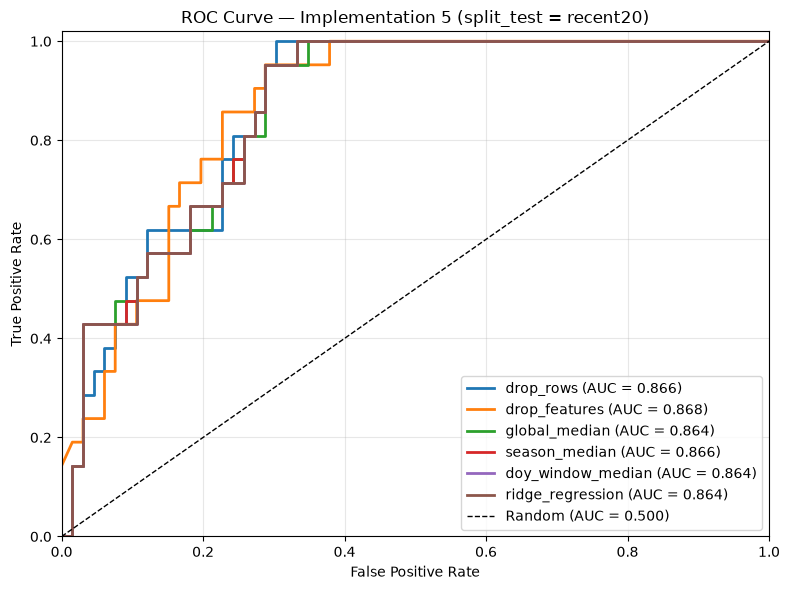

In [25]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

strategies_to_plot = (
    "drop_rows",
    "drop_features",
    "global_median",
    "season_median",
    "doy_window_median",
    "ridge_regression",
)

plt.figure(figsize=(8, 6))

for st in strategies_to_plot:
    folds = cv_folds(
        st, split_test="recent20", cv="loyo", season="drop",
        scale=True, one_hot_cluster=True, sin_doy=True
    )
    best = max(
        ({**evaluate_cfg(folds, cfg), "cfg": cfg} for cfg in configs()),
        key=lambda r: r["pooled_auc"]
    )
    cfg = best["cfg"]

    Xtv, ytv, Xte, yte = prepare_data(
        st, split_test="recent20", one_hot_cluster=True,
        sin_doy=True, season="drop", scale=True
    )
    final = make_lr(cfg).fit(Xtv.to_numpy(float), ytv.to_numpy())
    p_test = p1(final, Xte.to_numpy(float))

  
    fpr, tpr, _ = roc_curve(yte, p_test)
    auc_val = roc_auc_score(yte, p_test)
    plt.plot(fpr, tpr, linewidth=2, label=f"{st} (AUC = {auc_val:.3f})")


plt.plot([0, 1], [0, 1], "k--", linewidth=1, label="Random (AUC = 0.500)")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Implementation 5 (split_test = recent20)")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.02])
plt.grid(True, alpha=0.3)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()